# Table 3 — Statistical asymmetry of 4 × 4 binary matrices

The eight matrices are transcribed from the published table in reading
order, left to right and top to bottom. Black cells are encoded as `1`
and white cells as `0`.

The components follow the paper's order: upward translations ($B_1$),
leftward translations ($B_2$), reflection across the horizontal
centreline ($B_3$), reflection across the vertical centreline ($B_4$),
and quarter-turn rotations ($B_5$).

For each component, we compute the Hamming distances to the transformed
matrix, including the identity. We normalise the entropy of the distance
distribution by the logarithm of the number of transformations used and
multiply by the largest distance divided by 16. For translations, we
use shifts of zero, one, and two cells. Opposite shifts have equal
Hamming distances under periodic boundaries.

The table below shows the eight matrices in the published layout,
with the five computed statistical asymmetry components beside each
matrix. Each value is displayed at the precision used in the paper.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

# The published values specify the display precision for each score
examples = (
    ("1100/1100/1100/1100", ("0", "1", "0", "1", "0.75")),
    ("1111/1111/0000/0000", ("1", "0", "1", "0", "0.75")),
    ("1100/1100/0011/0011", ("1", "1", "1", "1", "0.5")),
    ("0101/1010/0101/1010", ("0.58", "0.58", "1", "1", "0.5")),
    ("0110/1001/1001/0110", ("1", "1", "0", "0", "0")),
    ("0110/0110/0110/0110", ("0", "1", "0", "0", "0.25")),
    ("1110/1110/1000/1000", ("0.5", "0.29", "0.5", "0.5", "0.75")),
    ("1110/1001/1001/0111", ("0.75", "0.75", "0.25", "0.25", "0.125")),
)


def asymmetry(grid, transformed_grids):
    distances = [
        np.count_nonzero(grid != transformed)
        for transformed in transformed_grids
    ]
    _, counts = np.unique(distances, return_counts=True)
    probabilities = counts / len(distances)
    entropy = -np.sum(probabilities * np.log(probabilities))
    return (entropy / np.log(len(distances))) * (max(distances) / grid.size)


def asymmetry_vector(grid):
    transformations = (
        [np.roll(grid, -shift, axis=0) for shift in range(3)],
        [np.roll(grid, -shift, axis=1) for shift in range(3)],
        [grid, np.flipud(grid)],
        [grid, np.fliplr(grid)],
        [np.rot90(grid, turn) for turn in range(4)],
    )
    return tuple(asymmetry(grid, group) for group in transformations)


table_entries = []

for matrix_rows, published in examples:
    grid = np.array([
        [int(cell) for cell in row]
        for row in matrix_rows.split("/")
    ])
    scores = asymmetry_vector(grid)
    displayed = tuple(
        f"{float(score) + 0.0:.{len(reference.partition('.')[2])}f}"
        for score, reference in zip(scores, published)
    )
    table_entries.append((grid, displayed))

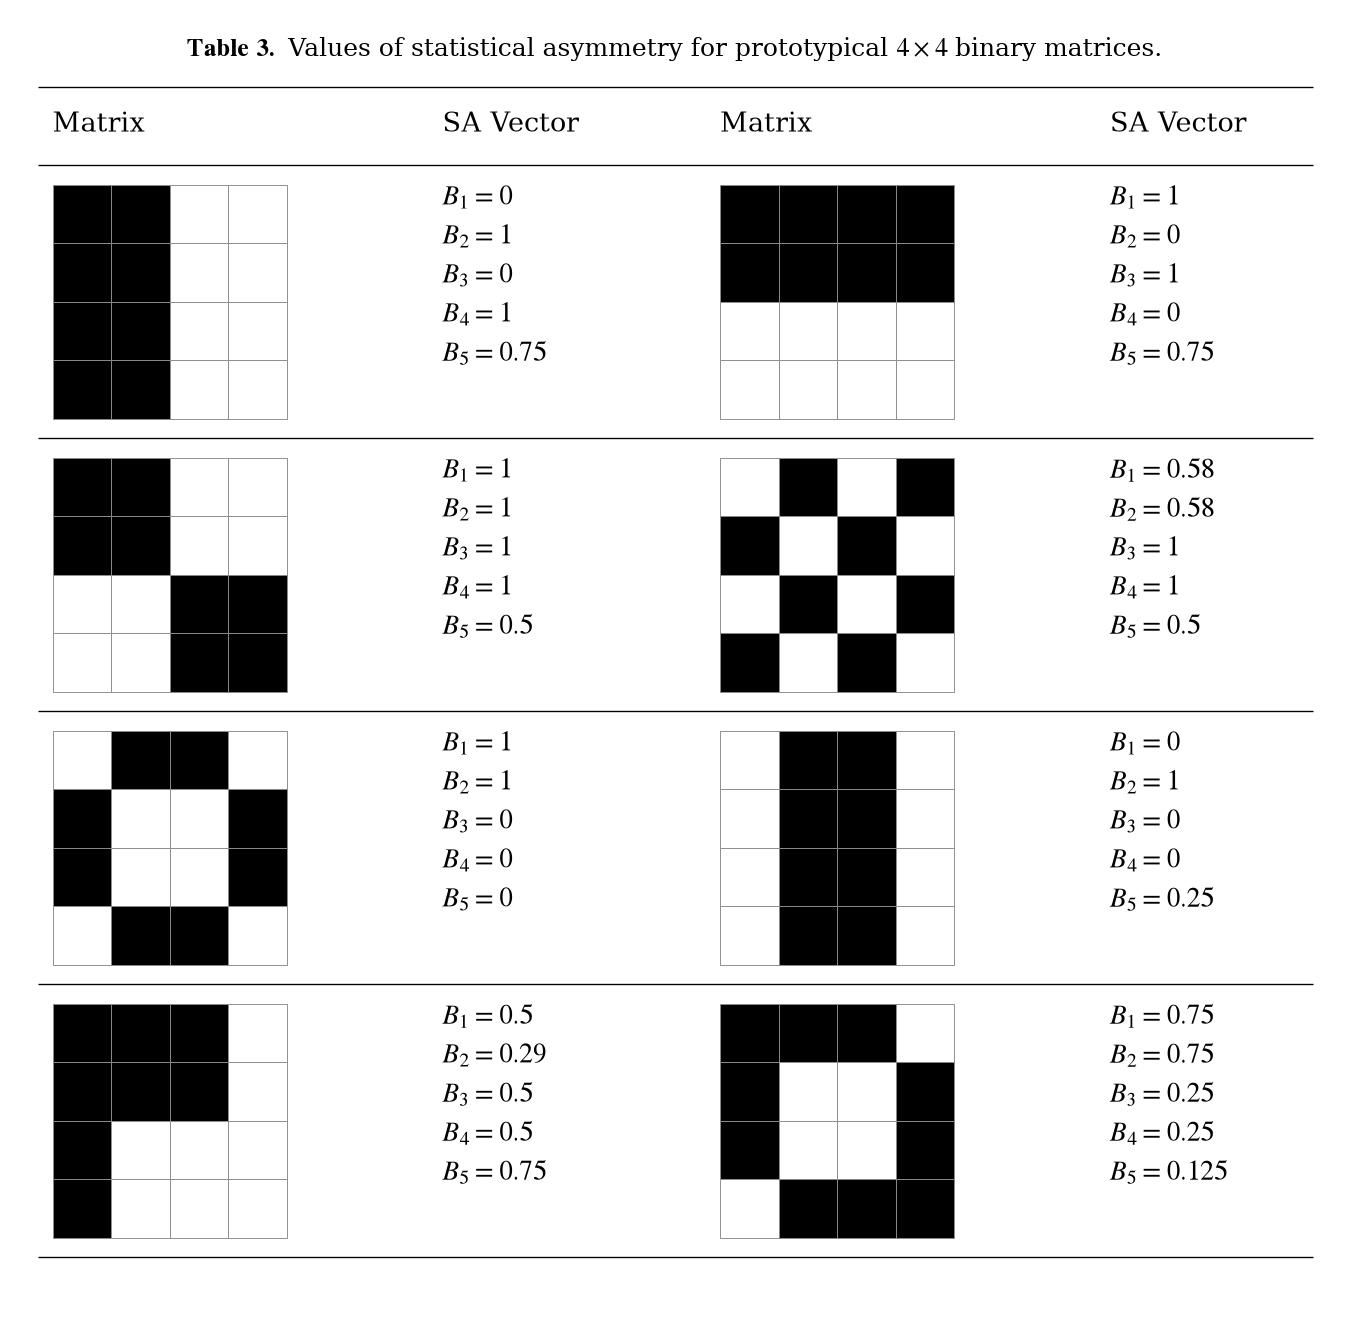

In [2]:
width, height = 8.8, 8.6
column_x = (0.25, 2.85, 4.70, 7.30)
square_size = 0.39
row_top = 7.60
row_height = 1.82

with plt.rc_context({
    "font.family": "serif",
    "mathtext.fontset": "stix",
    "text.color": "black",
}):
    fig, ax = plt.subplots(figsize=(width, height), dpi=150)
    fig.patch.set_facecolor("white")
    ax.set_xlim(0, width)
    ax.set_ylim(0, height)
    ax.set_aspect("equal")
    ax.axis("off")

    ax.text(
        width / 2, 8.37,
        r"$\mathbf{Table\ 3.}$ Values of statistical asymmetry for "
        r"prototypical $4 \times 4$ binary matrices.",
        ha="center", va="center", fontsize=12,
    )

    ax.hlines([8.12, row_top], 0.15, 8.65, color="black", linewidth=0.65)
    for x, heading in zip(
        column_x, ("Matrix", "SA Vector", "Matrix", "SA Vector")
    ):
        ax.text(x, 7.87, heading, va="center", fontsize=13)

    for index, (grid, values) in enumerate(table_entries):
        table_row, pair = divmod(index, 2)
        matrix_x = column_x[2 * pair]
        vector_x = column_x[2 * pair + 1]
        matrix_top = row_top - table_row * row_height - 0.13

        for (row, col), bit in np.ndenumerate(grid):
            ax.add_patch(
                Rectangle(
                    (matrix_x + col * square_size,
                     matrix_top - (row + 1) * square_size),
                    square_size,
                    square_size,
                    facecolor="black" if bit else "white",
                    edgecolor="0.55",
                    linewidth=0.45,
                )
            )

        for component, value in enumerate(values, start=1):
            ax.text(
                vector_x, matrix_top - 0.26 * (component - 1),
                rf"$B_{component} = {value}$",
                va="top", fontsize=13,
            )

    for row in range(1, 5):
        ax.hlines(
            row_top - row * row_height,
            0.15, 8.65, color="black", linewidth=0.65,
        )

    fig.subplots_adjust(left=0, right=1, bottom=0, top=1)
    plt.show()